# Mushroom harvest-weight model training

This notebook trains a regression model using the 200 records in `KABUTOMATE_200_Harvest_Training_Dataset-v3.docx` (converted to the companion CSV). Inputs are `Growing_Days`, `Humidity_pct`, `Temperature_C`, and `Air_Quality_CO2_ppm`; the target is `Weight_g`.

The notebook compares a growing-days-only baseline with models using all four inputs, evaluates the selected model on held-out records, and saves `predictive_harvest_weight_v3_model.pkl`, the artifact used by the production page. Rerunning the save cell replaces that active model artifact.

In [20]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load and validate the v3 data

Keep the v3 CSV beside this notebook. It is an extraction of the table in the DOCX and avoids needing an extra DOCX-reading package in the notebook environment.

In [21]:
dataset_filename = "KABUTOMATE_200_Harvest_Training_Dataset-v3.csv"
dataset_candidates = [
    Path.cwd() / dataset_filename,
    Path.cwd() / "mushroom_dashboard" / dataset_filename,
    Path.cwd() / "Capstone-Project" / "mushroom_dashboard" / dataset_filename,
    Path.cwd() / "Mushroom Capstone" / "Capstone-Project" / "mushroom_dashboard" / dataset_filename,
]
dataset_path = next((candidate for candidate in dataset_candidates if candidate.is_file()), None)
if dataset_path is None:
    searched_paths = ", ".join(str(candidate) for candidate in dataset_candidates)
    raise FileNotFoundError(f"Could not find {dataset_filename}. Searched: {searched_paths}")

required_columns = [
    "Growing_Days",
    "Weight_g",
    "Humidity_pct",
    "Temperature_C",
    "Air_Quality_CO2_ppm",
]
df = pd.read_csv(dataset_path)
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")
df = df[required_columns].copy()
for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors="raise")
if df.empty:
    raise ValueError("The v3 dataset contains no records.")
if df[required_columns].isna().any().any():
    raise ValueError("The v3 dataset contains missing values.")
if not np.isfinite(df[required_columns].to_numpy(dtype=float)).all():
    raise ValueError("The v3 dataset contains non-finite numeric values.")
if (df["Growing_Days"] <= 0).any() or (df["Weight_g"] <= 0).any():
    raise ValueError("Growing days and harvest weight must both be positive.")
if df["Growing_Days"].nunique() < 2:
    raise ValueError("At least two distinct growing-day values are required for training.")

features = [
    "Growing_Days",
    "Humidity_pct",
    "Temperature_C",
    "Air_Quality_CO2_ppm",
]
target = "Weight_g"
observed_days = sorted(df["Growing_Days"].unique().tolist())
print(f"Loaded {len(df)} records from {dataset_path}")
print(f"Growing-day values: {observed_days}")
display(df.head())

Loaded 200 records from c:\Users\Dan Kirvy\Desktop\Capstone Project\Mushroom Capstone\Capstone-Project\mushroom_dashboard\KABUTOMATE_200_Harvest_Training_Dataset-v3.csv
Growing-day values: [2, 3, 4]


,Growing_Days,Weight_g,Humidity_pct,Temperature_C,Air_Quality_CO2_ppm
0,3,802.9,83.9,22.1,778
1,4,894.1,85.9,22.5,580
2,2,678.3,80.4,24.8,753
3,2,737.8,90.6,26.8,713
4,2,755.9,93.4,22.9,894


## 2. Explore the measurements

,count,mean,std,min,25%,50%,75%,max
Growing_Days,200.0,2.83,0.72,2.0,2.00,3.00,3.00,4.0
Weight_g,200.0,811.44,90.43,637.4,735.10,810.25,871.38,1018.0
Humidity_pct,200.0,86.80,3.85,80.0,83.68,86.55,90.20,93.6
Temperature_C,200.0,24.81,1.47,22.1,23.58,24.75,26.10,27.5
Air_Quality_CO2_ppm,200.0,858.02,179.75,550.0,705.75,852.00,1015.00,1150.0


,count,mean,std,min,max
Growing_Days,,,,,
2,71,718.16,36.18,637.4,825.9
3,92,827.31,38.52,734.1,912.0
4,37,950.95,33.18,891.8,1018.0


,Correlation with Weight_g
Weight_g,1.000000
Growing_Days,0.913701
Humidity_pct,0.194355
Temperature_C,-0.074621
Air_Quality_CO2_ppm,-0.099137


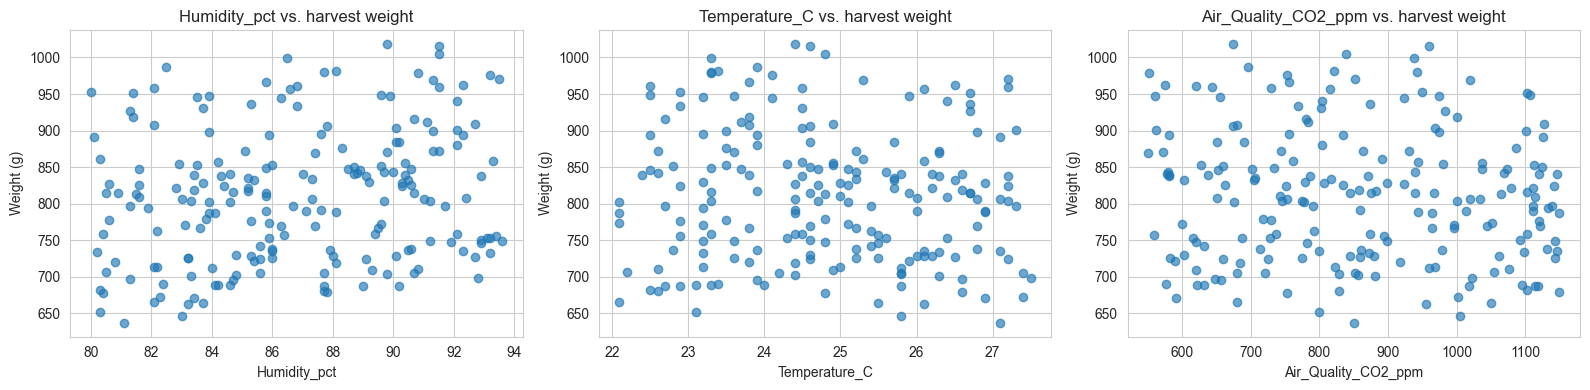

In [22]:
display(df.describe().T.round(2))
display(
    df.groupby("Growing_Days")["Weight_g"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)
display(df.corr(numeric_only=True)[target].sort_values(ascending=False).to_frame("Correlation with Weight_g"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, ["Humidity_pct", "Temperature_C", "Air_Quality_CO2_ppm"]):
    ax.scatter(df[feature], df[target], alpha=0.65)
    ax.set_xlabel(feature)
    ax.set_ylabel("Weight (g)")
    ax.set_title(f"{feature} vs. harvest weight")
plt.tight_layout()
plt.show()

## 3. Select and train a model

Use a stratified holdout so each growing-day group appears in both sets. Select between linear regression and random forest using 5-fold cross-validation on the training split, then report test metrics on the untouched holdout.

In [23]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["Growing_Days"],
)

candidate_models = {
    "LinearRegression": LinearRegression(),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
    ),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []
for model_name, candidate in candidate_models.items():
    fold_mae = -cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
    )
    cv_results.append({
        "model_name": model_name,
        "mean_cv_mae_g": float(fold_mae.mean()),
        "std_cv_mae_g": float(fold_mae.std()),
    })

selected_model_name = min(cv_results, key=lambda result: result["mean_cv_mae_g"])["model_name"]
selected_model = candidate_models[selected_model_name]
selected_model.fit(X_train, y_train)
y_test_pred = selected_model.predict(X_test)

baseline_model = LinearRegression().fit(X_train[["Growing_Days"]], y_train)
y_baseline_pred = baseline_model.predict(X_test[["Growing_Days"]])

test_metrics = {
    "mae_g": float(mean_absolute_error(y_test, y_test_pred)),
    "rmse_g": float(np.sqrt(mean_squared_error(y_test, y_test_pred))),
    "r2": float(r2_score(y_test, y_test_pred)),
}
baseline_test_metrics = {
    "mae_g": float(mean_absolute_error(y_test, y_baseline_pred)),
    "rmse_g": float(np.sqrt(mean_squared_error(y_test, y_baseline_pred))),
    "r2": float(r2_score(y_test, y_baseline_pred)),
}
cv_results_df = pd.DataFrame(cv_results).sort_values("mean_cv_mae_g")
print(f"Selected model by CV MAE: {selected_model_name}")
print(f"Selected model held-out metrics: {test_metrics}")
print(f"Growing-days baseline held-out metrics: {baseline_test_metrics}")

# Refit the selected model on all provided records for the saved artifact.
final_model = candidate_models[selected_model_name].fit(X, y)

Selected model by CV MAE: RandomForestRegressor
Selected model held-out metrics: {'mae_g': 27.1756810971629, 'rmse_g': 31.20765244075416, 'r2': 0.8858797335787868}
Growing-days baseline held-out metrics: {'mae_g': 28.778093403205908, 'rmse_g': 34.75851613062049, 'r2': 0.8584326732500142}


## 4. Review model performance

,model_name,mean_cv_mae_g,std_cv_mae_g
1,RandomForestRegressor,25.784,1.833
0,LinearRegression,26.008,2.737


,Model,mae_g,rmse_g,r2
0,RandomForestRegressor,27.176,31.208,0.886
1,Growing_Days-only baseline,28.778,34.759,0.858


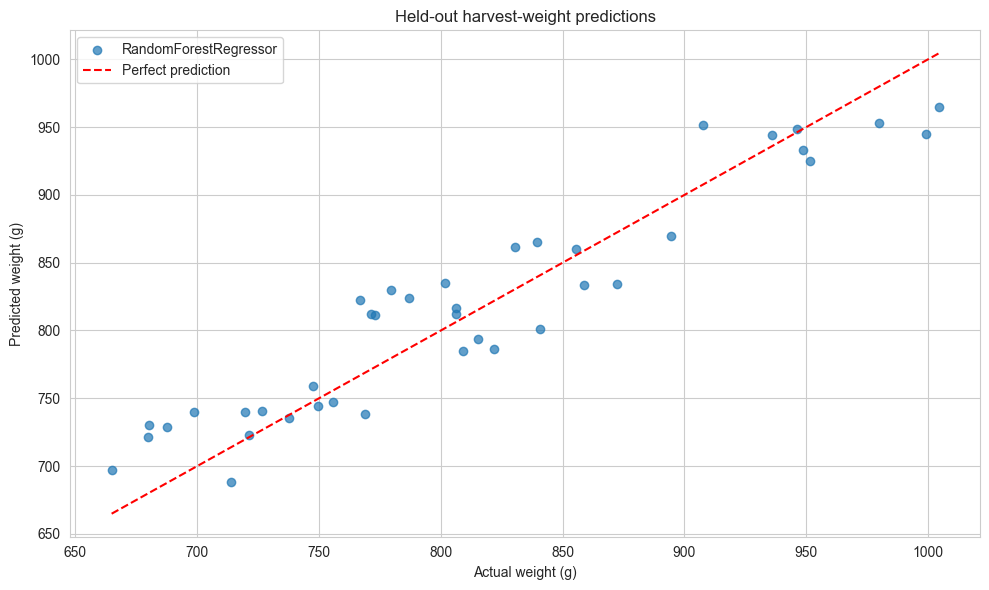

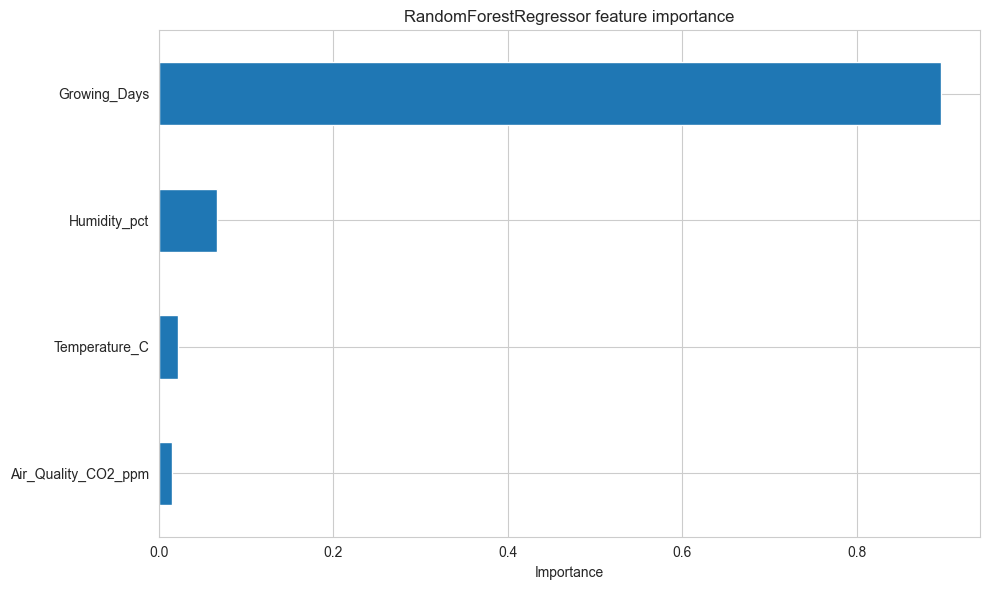

In [24]:
display(cv_results_df.round(3))
display(pd.DataFrame([
    {"Model": selected_model_name, **test_metrics},
    {"Model": "Growing_Days-only baseline", **baseline_test_metrics},
]).round(3))

fig, ax = plt.subplots()
ax.scatter(y_test, y_test_pred, alpha=0.7, label=selected_model_name)
plot_min = min(float(y_test.min()), float(y_test_pred.min()))
plot_max = max(float(y_test.max()), float(y_test_pred.max()))
ax.plot([plot_min, plot_max], [plot_min, plot_max], "r--", label="Perfect prediction")
ax.set_title("Held-out harvest-weight predictions")
ax.set_xlabel("Actual weight (g)")
ax.set_ylabel("Predicted weight (g)")
ax.legend()
plt.tight_layout()
plt.show()

if hasattr(final_model, "feature_importances_"):
    importance = pd.Series(final_model.feature_importances_, index=features).sort_values()
elif hasattr(final_model, "coef_"):
    importance = pd.Series(np.abs(final_model.coef_), index=features).sort_values()
else:
    importance = None
if importance is not None:
    importance.plot(kind="barh", title=f"{selected_model_name} feature importance")
    plt.xlabel("Importance" if hasattr(final_model, "feature_importances_") else "Absolute coefficient")
    plt.tight_layout()
    plt.show()

## 5. Try a prediction

Provide all four inputs. The helper checks each value against the range seen in the v3 dataset rather than extrapolating beyond it.

In [25]:
feature_ranges = {
    feature: [float(df[feature].min()), float(df[feature].max())]
    for feature in features
}

def predict_harvest_weight(growing_days, humidity_pct, temperature_c, air_quality_co2_ppm):
    input_data = pd.DataFrame([{
        "Growing_Days": float(growing_days),
        "Humidity_pct": float(humidity_pct),
        "Temperature_C": float(temperature_c),
        "Air_Quality_CO2_ppm": float(air_quality_co2_ppm),
    }], columns=features)
    if not np.isfinite(input_data.to_numpy(dtype=float)).all():
        raise ValueError("All prediction inputs must be finite numbers.")
    for feature in features:
        minimum, maximum = feature_ranges[feature]
        value = float(input_data.iloc[0][feature])
        if value < minimum or value > maximum:
            raise ValueError(f"{feature} must be within the observed range [{minimum:g}, {maximum:g}].")
    return float(final_model.predict(input_data)[0])

example = df.iloc[0]
example_prediction = predict_harvest_weight(
    example["Growing_Days"],
    example["Humidity_pct"],
    example["Temperature_C"],
    example["Air_Quality_CO2_ppm"],
)
print(f"Example: {example['Growing_Days']:g} days -> {example_prediction:.1f} g predicted weight")

Example: 3 days -> 813.9 g predicted weight


## 6. Save the v3 production model

The production website loads this artifact from the Django project root. Retraining replaces the active artifact; deploy the updated model file together with the code.

In [26]:
model_artifact = {
    "model": final_model,
    "model_name": selected_model_name,
    "features": features,
    "target": target,
    "training_data": {
        "dataset_file": dataset_path.name,
        "rows": int(len(df)),
        "growing_days_observed": observed_days,
        "feature_ranges": feature_ranges,
    },
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_test_metrics,
    "cross_validation": cv_results,
}
model_path = dataset_path.with_name("predictive_harvest_weight_v3_model.pkl")
with model_path.open("wb") as model_file:
    pickle.dump(model_artifact, model_file)

print(f"v3 production model saved to: {model_path}")
print(f"Model inputs: {features}")
print(f"Prediction target: {target}")

v3 production model saved to: c:\Users\Dan Kirvy\Desktop\Capstone Project\Mushroom Capstone\Capstone-Project\mushroom_dashboard\predictive_harvest_weight_v3_model.pkl
Model inputs: ['Growing_Days', 'Humidity_pct', 'Temperature_C', 'Air_Quality_CO2_ppm']
Prediction target: Weight_g
